# Projet SCI 1402 - Efficacité énergétique des véhicules au Canada

## Notebook 03 - Analyses complémentaires et finalisation des résultats

**Source des données :** Ressources naturelles Canada (RNCan)  
**Période étudiée :** 2015 à 2024  

---

### Objectif du notebook

Ce troisième notebook constitue la dernière étape du développement et de l'analyse du projet. Il poursuit les travaux de préparation des données, de modélisation et de validation réalisés dans les deux notebooks précédents.

Son objectif principal est d'approfondir la compréhension des performances du modèle forêt aléatoire, particulièrement la diminution de sa précision observée entre 2023 et 2024, puis de consolider les résultats en vue de leur présentation dans les travaux finaux du cours.

Il vise également à produire des tableaux et des figures permettant de communiquer clairement les résultats obtenus et les limites du modèle.

### Méthodologie

Le modèle forêt aléatoire est entraîné sur les données de 2015 à 2022 et évalué sur les observations des années 2023 et 2024.

Les analyses complémentaires et les étapes de finalisation comprennent :

  1. **Décomposition de la variation de la MAE (M025)** : Distinction entre les effets associés aux changements de composition des catégories de véhicules et ceux associés aux variations des erreurs à l'intérieur des catégories.

  2. **Analyse de la fréquence des configurations (M026)** : Examen de la précision des prédictions selon la fréquence des combinaisons de caractéristiques observées dans les données d'entraînement, notamment pour les configurations nouvelles ou rares.

  3. **Analyse de la dispersion des erreurs (M027)** : Étude des relations entre le niveau de consommation prédite et l'amplitude des erreurs, à l'aide de statistiques descriptives, de visualisations et de coefficients de corrélation.

  4. **Consolidation des résultats de modélisation (M028)** : Comparaison des performances du modèle forêt aléatoire avec celles des modèles de référence et regroupement des résultats des validations chronologiques.

  5. **Production des figures et tableaux définitifs (M029)** : Création de visualisations illustrant les performances des modèles, les prédictions, la distribution des erreurs et l'importance des variables explicatives.

  6. **Exportation et vérification des résultats (M030)** : Sauvegarde des tableaux et figures, création d'une archive des résultats et vérification de la reproductibilité des analyses.

### Principaux résultats

Les analyses confirment que le modèle forêt aléatoire obtient les meilleures performances parmi les trois modèles évalués, avec une erreur absolue moyenne (MAE) de 0,610 L/100 km et un coefficient R² de 0,897 sur le jeu de test 2023–2024.

Une diminution de la précision est toutefois observée en 2024, avec une MAE de 0,676 L/100 km, comparativement à 0,553 L/100 km en 2023.

Les analyses complémentaires montrent que cette dégradation est principalement associée à une augmentation des erreurs à l'intérieur des catégories de véhicules plutôt qu'à une modification de leur répartition.

L'importance des variables par permutation indique également que la cylindrée constitue la variable la plus déterminante pour la précision prédictive du modèle, suivie de la catégorie de véhicule et de la transmission.

### Résultats produits

Ce notebook permet de produire les principaux livrables techniques du projet :

  - Des tableaux consolidant les performances des modèles et les résultats des analyses.
  - Cinq figures définitives illustrant les principaux résultats.
  - Des fichiers CSV facilitant la réutilisation des données calculées.
  - Une archive ZIP regroupant les tableaux et les figures.
  - Un ensemble d'analyses reproductibles dans Google Colab.

Ces éléments serviront à documenter le produit final fonctionnel et à préparer la communication des résultats dans le cadre du cours SCI 1402.

### Portée et limites

Les données étudiées correspondent aux configurations de véhicules répertoriées par Ressources naturelles Canada et ne représentent pas les volumes de ventes de véhicules.

Les performances obtenues sont propres aux données, aux variables explicatives et au protocole d'évaluation retenus.

Les analyses complémentaires sont principalement descriptives et exploratoires. Elles permettent de caractériser les erreurs du modèle et d'identifier certaines associations, mais ne démontrent pas de relations causales.

Enfin, la reproductibilité a été vérifiée par une exécution complète du notebook dans un environnement Google Colab redémarré, sans erreur d'exécution.

In [ ]:
# Notebook 03 - Initialisation du projet SCI 1402

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

from pathlib import Path

# Répertoire des données originales
dossier = Path("/content/data/raw")
dossier.mkdir(parents=True, exist_ok=True)

nom_fichier = (
    "am2015-2024-cotes-de-consommation-de-carburant.csv"
)
fichier = dossier / nom_fichier

# Même source RNCan que dans le notebook 02
url = (
    "https://open.canada.ca/data/dataset/"
    "98f1a129-f628-4ce4-b24d-6f16bf24dd64/"
    "resource/581ab81d-fe7f-4beb-9f31-e1b8e7552cb6/"
    "download/am2015-2024-cotes-de-consommation-de-carburant.csv"
)

if not fichier.exists():
    reponse = requests.get(url, timeout=60)
    reponse.raise_for_status()
    fichier.write_bytes(reponse.content)

# Lecture du fichier original
df = pd.read_csv(fichier, encoding="cp1252")

# Copie indépendante pour les analyses
df_analyse = df.copy()

# Reproduction de la normalisation des catégories
df_analyse["Catégorie de véhicule"] = (
    df_analyse["Catégorie de véhicule"].str.strip()
)

print("Dimensions :", df_analyse.shape)
print(
    "Catégories :",
    df_analyse["Catégorie de véhicule"].nunique()
)
print("Fichier original conservé :", fichier.exists())


Dimensions : (10060, 15)
Catégories : 16
Fichier original conservé : True


**Préparation et reconstitution du modèle forêt aléatoire**

Je reprends le modèle forêt aléatoire utilisé dans les notebooks précédents afin de reproduire les prédictions pour 2023 et 2024.

Je conserve les mêmes variables, les mêmes paramètres et la même séparation chronologique des données pour assurer la comparabilité des résultats.

In [ ]:
# Notebook 03 - Reconstitution du modèle de référence

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Variables explicatives
variables_numeriques = [
    "Année modèle",
    "Cylindrée (L)",
    "Cylindres"
]

variables_categorielles = [
    "Catégorie de véhicule",
    "Transmission",
    "Type de carburant"
]

variables = variables_numeriques + variables_categorielles
cible = "Combinée (L/100 km)"

# Séparation chronologique
train = df_analyse["Année modèle"] <= 2022
test = df_analyse["Année modèle"] >= 2023

X_train = df_analyse.loc[train, variables]
X_test = df_analyse.loc[test, variables]
y_train = df_analyse.loc[train, cible]
y_test = df_analyse.loc[test, cible]

# Préparation des variables
preparation = ColumnTransformer([
    (
        "num",
        SimpleImputer(strategy="median"),
        variables_numeriques
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(
                strategy="most_frequent"
            )),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ]),
        variables_categorielles
    )
])

# Modèle forêt aléatoire (Random Forest)
modele_rf = Pipeline([
    ("preparation", preparation),
    ("modele", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Entraînement et prédictions
modele_rf.fit(X_train, y_train)
y_pred_rf = modele_rf.predict(X_test)

# Évaluation
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)

print("Entraînement :", len(X_train))
print("Test :", len(X_test))
print(f"MAE  : {mae:.3f} L/100 km")
print(f"RMSE : {rmse:.3f} L/100 km")
print(f"R²   : {r2:.3f}")


Entraînement : 8352
Test : 1708
MAE  : 0.610 L/100 km
RMSE : 0.910 L/100 km
R²   : 0.897


In [ ]:
# Notebook 03 - Tableau des prédictions et des erreurs

resultats_m020 = df_analyse.loc[test, [
    "Année modèle",
    "Marque",
    "Modèle",
    "Catégorie de véhicule",
    "Cylindrée (L)",
    "Cylindres",
    "Transmission",
    "Type de carburant",
    "Combinée (L/100 km)"
]].copy()

resultats_m020["Prédiction (L/100 km)"] = y_pred_rf

resultats_m020["Résidu"] = (
    resultats_m020["Combinée (L/100 km)"]
    - resultats_m020["Prédiction (L/100 km)"]
)

resultats_m020["Erreur absolue"] = (
    resultats_m020["Résidu"].abs()
)

print("Nombre de prédictions :", len(resultats_m020))

print("\nMAE par année :")
print(
    resultats_m020
    .groupby("Année modèle")["Erreur absolue"]
    .mean()
    .round(3)
    .to_string()
)


Nombre de prédictions : 1708

MAE par année :
Année modèle
2023    0.553
2024    0.676


---

**M025 - Décomposition de la variation des erreurs entre 2023 et 2024**

Dans cette manipulation, je vais chercher à mieux comprendre l'augmentation de la MAE entre 2023 et 2024.

Je vais distinguer deux effets : le changement dans la proportion des différentes catégories de véhicules et le changement des erreurs moyennes à l'intérieur de ces catégories.

Cette analyse permettra de quantifier leur contribution à la variation globale de la MAE. Elle demeure descriptive et ne permet pas d'établir une relation de cause à effet.

In [ ]:
# M025 - Décomposition de la variation de la MAE
# Comparaison 2023 et 2024

categorie = "Catégorie de véhicule"

stats = (
    resultats_m020
    .groupby([categorie, "Année modèle"])
    .agg(
        n=("Erreur absolue", "size"),
        mae=("Erreur absolue", "mean")
    )
    .unstack("Année modèle")
)

# Effectifs et proportions
n23 = stats[("n", 2023)].fillna(0)
n24 = stats[("n", 2024)].fillna(0)

p23 = n23 / n23.sum()
p24 = n24 / n24.sum()

# MAE de chaque catégorie
m23 = stats[("mae", 2023)]
m24 = stats[("mae", 2024)]

# Catégories présentes les deux années
communes = (n23 > 0) & (n24 > 0)

# Effet du changement de composition
effet_composition = (
    (p24[communes] - p23[communes])
    * (m23[communes] + m24[communes]) / 2
).sum()

# Effet de la variation des erreurs internes
effet_erreurs = (
    (m24[communes] - m23[communes])
    * (p23[communes] + p24[communes]) / 2
).sum()

# Catégories présentes une seule année
seulement_2023 = (n23 > 0) & (n24 == 0)
seulement_2024 = (n24 > 0) & (n23 == 0)

effet_categories_absentes = (
    -(p23[seulement_2023] * m23[seulement_2023]).sum()
    + (p24[seulement_2024] * m24[seulement_2024]).sum()
)

# Variation réelle de la MAE
mae23 = resultats_m020.loc[
    resultats_m020["Année modèle"] == 2023,
    "Erreur absolue"
].mean()

mae24 = resultats_m020.loc[
    resultats_m020["Année modèle"] == 2024,
    "Erreur absolue"
].mean()

variation_reelle = mae24 - mae23

# Vérification de la décomposition
variation_decomposee = (
    effet_composition
    + effet_erreurs
    + effet_categories_absentes
)

print(f"MAE 2023 : {mae23:.4f}")
print(f"MAE 2024 : {mae24:.4f}")
print(f"Variation réelle : {variation_reelle:+.4f}")

print("\nDécomposition de la variation :")
print(f"Effet composition : {effet_composition:+.4f}")
print(f"Effet erreurs internes : {effet_erreurs:+.4f}")
print(
    "Effet catégories présentes une seule année : "
    f"{effet_categories_absentes:+.4f}"
)

print(f"\nSomme des effets : {variation_decomposee:+.4f}")

assert np.isclose(
    variation_reelle,
    variation_decomposee,
    atol=1e-10
)

print("Vérification : OK")


MAE 2023 : 0.5526
MAE 2024 : 0.6759
Variation réelle : +0.1233

Décomposition de la variation :
Effet composition : +0.0083
Effet erreurs internes : +0.1160
Effet catégories présentes une seule année : -0.0011

Somme des effets : +0.1233
Vérification : OK


**Interprétation des résultats - M025**

La MAE du modèle forêt aléatoire passe de 0,5526 L/100 km en 2023 à 0,6759 L/100 km en 2024, soit une augmentation d'environ 22,3 %.

La décomposition montre que la variation des erreurs à l'intérieur des catégories communes contribue pour 0,1160 L/100 km à cette hausse, ce qui représente environ 94 % de la variation nette.

Le changement de répartition des catégories contribue pour seulement 0,0083 L/100 km. La contribution nette des catégories présentes une seule année est légèrement négative, à environ −0,0011 L/100 km.

Ces résultats indiquent que l'augmentation de la MAE en 2024 est principalement associée à des erreurs plus importantes à l'intérieur des catégories de véhicules, plutôt qu'à une modification de leur répartition.

Cette décomposition demeure descriptive. Elle ne permet pas d'identifier précisément les causes de la diminution de la performance prédictive.

---

**M026 - Analyse des configurations nouvelles et peu représentées**

Dans cette manipulation, je vais examiner si les erreurs de prédiction du modèle forêt aléatoire sont associées à des configurations de véhicules nouvelles ou peu représentées dans les données d'entraînement.

Je vais d'abord définir une configuration à partir de la catégorie du véhicule, de sa transmission et de son type de carburant.

Je comparerai ensuite les configurations présentes dans les années 2023 et 2024 à celles observées durant l'entraînement, soit de 2015 à 2022.

Cette première étape permettra de déterminer la proportion de configurations déjà connues et nouvelles, sans encore établir de lien avec les erreurs de prédiction.

In [ ]:
# M026 - Étape 1
# Identifier les configurations nouvelles en 2023 et 2024

colonnes_configuration = [
    "Catégorie de véhicule",
    "Transmission",
    "Type de carburant"
]

# Configurations présentes dans l'entraînement
configurations_train = (
    df_analyse.loc[train, colonnes_configuration]
    .drop_duplicates()
    .copy()
)

# Configurations présentes dans le test
configurations_test = (
    resultats_m020[
        ["Année modèle"] + colonnes_configuration
    ].copy()
)

# Comparaison avec les configurations d'entraînement
comparaison_configurations = configurations_test.merge(
    configurations_train.assign(
        Configuration_connue=True
    ),
    on=colonnes_configuration,
    how="left",
    validate="many_to_one"
)

comparaison_configurations["Configuration connue"] = (
    comparaison_configurations["Configuration_connue"]
    .eq(True)
)

# Résumé par année
resume_configurations = (
    comparaison_configurations
    .groupby("Année modèle")
    .agg(
        N=("Configuration connue", "size"),
        Configurations_connues=(
            "Configuration connue", "sum"
        )
    )
)

resume_configurations["Configurations_nouvelles"] = (
    resume_configurations["N"]
    - resume_configurations["Configurations_connues"]
)

resume_configurations["Pct_nouvelles"] = (
    resume_configurations["Configurations_nouvelles"]
    / resume_configurations["N"] * 100
)

print(
    "Nombre de configurations distinctes "
    "dans l'entraînement :",
    len(configurations_train)
)

print("\nConfigurations nouvelles par année :")
print(resume_configurations.round(2).to_string())

print("\nExemples de configurations nouvelles :")
exemples_nouveaux = (
    comparaison_configurations.loc[
        ~comparaison_configurations["Configuration connue"],
        ["Année modèle"] + colonnes_configuration
    ]
    .drop_duplicates()
    .head(15)
)

if exemples_nouveaux.empty:
    print("Aucune configuration nouvelle détectée.")
else:
    print(exemples_nouveaux.to_string(index=False))


Nombre de configurations distinctes dans l'entraînement : 329

Configurations nouvelles par année :
                N  Configurations_connues  Configurations_nouvelles  Pct_nouvelles
Année modèle                                                                      
2023          919                     912                         7           0.76
2024          789                     769                        20           2.53

Exemples de configurations nouvelles :
 Année modèle                 Catégorie de véhicule Transmission Type de carburant
         2023               Camionnette : ordinaire          A10                 E
         2023                           Deux places          AS9                 Z
         2024               Camionnette : ordinaire          A10                 E
         2024 Véhicule utilitaire sport : ordinaire          AM8                 Z
         2024     Véhicule utilitaire sport : petit          AV1                 X
         2024                 

**M026 - Fréquence des configurations et erreurs de prédiction**

Après avoir identifié les configurations nouvelles en 2023 et 2024, je vais examiner si les configurations peu représentées dans les données d'entraînement présentent des erreurs de prédiction plus élevées.

Je vais compter le nombre d'observations de chaque configuration entre 2015 et 2022, puis regrouper les véhicules de 2023 et 2024 selon cette fréquence.

Je comparerai ensuite la MAE des différents groupes pour déterminer si la rareté d'une configuration est associée à une diminution de la précision du modèle.

In [ ]:
# M026 - Étape 2
# Fréquence des configurations dans l'entraînement

# Nombre d'observations par configuration
frequences_train = (
    df_analyse.loc[train]
    .groupby(colonnes_configuration)
    .size()
    .reset_index(name="Frequence_train")
)

# Ajouter les fréquences aux prédictions du test
analyse_frequences = resultats_m020.merge(
    frequences_train,
    on=colonnes_configuration,
    how="left",
    validate="many_to_one"
)

# Les configurations absentes de l'entraînement
# reçoivent une fréquence de zéro
analyse_frequences["Frequence_train"] = (
    analyse_frequences["Frequence_train"]
    .fillna(0)
    .astype(int)
)

# Classification des fréquences
analyse_frequences["Groupe_frequence"] = pd.cut(
    analyse_frequences["Frequence_train"],
    bins=[-1, 0, 5, 20, 100, np.inf],
    labels=[
        "Nouvelle",
        "Très rare",
        "Rare",
        "Fréquente",
        "Très fréquente"
    ]
)

# Calcul de la MAE par année et groupe
resume_frequences = (
    analyse_frequences
    .groupby(
        ["Année modèle", "Groupe_frequence"],
        observed=True
    )
    .agg(
        N=("Erreur absolue", "size"),
        MAE=("Erreur absolue", "mean")
    )
    .reset_index()
)

resume_frequences["Pct_annee"] = (
    resume_frequences["N"]
    / resume_frequences.groupby("Année modèle")["N"]
      .transform("sum")
    * 100
)

print("Erreurs selon la fréquence des configurations :")
print(
    resume_frequences
    .round(3)
    .to_string(index=False)
)

# Vérification des effectifs
print("\nTotal des observations par année :")
print(
    analyse_frequences
    .groupby("Année modèle")
    .size()
    .to_string()
)


Erreurs selon la fréquence des configurations :
 Année modèle Groupe_frequence   N   MAE  Pct_annee
         2023         Nouvelle   7 0.630      0.762
         2023        Très rare  43 0.491      4.679
         2023             Rare 126 0.407     13.711
         2023        Fréquente 412 0.472     44.831
         2023   Très fréquente 331 0.715     36.017
         2024         Nouvelle  20 0.806      2.535
         2024        Très rare  40 0.591      5.070
         2024             Rare 114 0.599     14.449
         2024        Fréquente 336 0.566     42.586
         2024   Très fréquente 279 0.843     35.361

Total des observations par année :
Année modèle
2023    919
2024    789


**Interprétation des résultats - M026**

L'analyse des configurations montre que la proportion de véhicules présentant une combinaison de catégorie, transmission et carburant absente des données d'entraînement passe de 0,76 % en 2023 à 2,53 % en 2024.

Cependant, les configurations nouvelles ne présentent pas systématiquement les erreurs les plus importantes. En 2024, leur MAE atteint 0,806 L/100 km, tandis que celle des configurations très fréquentes atteint 0,843 L/100 km.

La MAE augmente entre 2023 et 2024 dans les cinq groupes de fréquence étudiés. Cette observation indique que la diminution de la précision ne se limite pas aux configurations nouvelles ou peu représentées.

Les résultats ne permettent donc pas de considérer la rareté des configurations comme l'explication principale de la hausse globale de la MAE. D'autres caractéristiques des véhicules, notamment celles qui ne sont pas prises en compte dans cette définition simplifiée d'une configuration, pourraient intervenir.

Cette analyse demeure descriptive et ne permet pas d'établir les causes exactes des différences observées.

In [ ]:
# M026 - Étape 3
# Contribution des groupes à la MAE globale en 2024

donnees_2024 = analyse_frequences.loc[
    analyse_frequences["Année modèle"] == 2024
].copy()

contributions_2024 = (
    donnees_2024
    .groupby("Groupe_frequence", observed=True)
    .agg(
        N=("Erreur absolue", "size"),
        Somme_erreurs=("Erreur absolue", "sum"),
        MAE=("Erreur absolue", "mean")
    )
)

# Part de chaque groupe dans la somme des erreurs absolues
contributions_2024["Part_erreurs_pct"] = (
    contributions_2024["Somme_erreurs"]
    / contributions_2024["Somme_erreurs"].sum()
    * 100
)

# Contribution additive à la MAE globale
contributions_2024["Contribution_MAE"] = (
    contributions_2024["Somme_erreurs"]
    / len(donnees_2024)
)

print("Contribution des groupes à la MAE en 2024 :")
print(
    contributions_2024[
        ["N", "MAE", "Part_erreurs_pct", "Contribution_MAE"]
    ].round(3).to_string()
)

print("\nVérification :")
print(
    "Somme des contributions :",
    round(contributions_2024["Contribution_MAE"].sum(), 4)
)

print(
    "MAE globale 2024 :",
    round(donnees_2024["Erreur absolue"].mean(), 4)
)


Contribution des groupes à la MAE en 2024 :
                    N    MAE  Part_erreurs_pct  Contribution_MAE
Groupe_frequence                                                
Nouvelle           20  0.806             3.024             0.020
Très rare          40  0.591             4.430             0.030
Rare              114  0.599            12.812             0.087
Fréquente         336  0.566            35.635             0.241
Très fréquente    279  0.843            44.100             0.298

Vérification :
Somme des contributions : 0.6759
MAE globale 2024 : 0.6759


**Conclusion - M026**

L'analyse de la contribution des groupes de fréquence montre que les configurations fréquentes et très fréquentes représentent ensemble environ 79,7 % de la somme des erreurs absolues en 2024.

À l'inverse, les configurations nouvelles ne contribuent qu'à environ 3,0 % de cette somme, malgré une MAE relativement élevée de 0,806 L/100 km.

Les configurations très fréquentes présentent la MAE la plus élevée, soit 0,843 L/100 km, et représentent à elles seules 44,1 % des erreurs absolues.

Ces résultats indiquent que les configurations nouvelles ne constituent pas, à elles seules, une explication suffisante de la diminution de la précision du modèle en 2024.

La fréquence d'une combinaison de catégorie, transmission et carburant ne garantit pas une meilleure prédiction. Cette observation pourrait notamment refléter la diversité des véhicules regroupés sous une même configuration.

L'analyse demeure descriptive et ne permet pas d'identifier les causes exactes des erreurs.

---

**M027 - Analyse de la dispersion des erreurs selon la consommation prédite**

Dans cette manipulation, je vais examiner la relation entre la consommation prédite par le modèle forêt aléatoire et les erreurs de prédiction.

Les analyses précédentes ont montré que les erreurs étaient généralement plus importantes pour les véhicules ayant une consommation réelle élevée.

Je vais maintenant regrouper les observations selon leur consommation prédite afin de comparer l'erreur absolue moyenne (MAE), la dispersion des résidus et le biais moyen.

Cette analyse permettra également de vérifier si les différences observées entre 2023 et 2024 sont présentes dans plusieurs niveaux de consommation prédite.

Les résultats demeureront descriptifs et ne permettront pas, à eux seuls, de démontrer une hétéroscédasticité statistique.

In [ ]:
# M027 - Étape 1
# Erreurs selon les plages de consommation prédite

donnees_m027 = resultats_m020.copy()

# Définition des plages de consommation prédite
bornes = [0, 8, 10, 12, 14, np.inf]

etiquettes = [
    "< 8",
    "8 à < 10",
    "10 à < 12",
    "12 à < 14",
    "≥ 14"
]

donnees_m027["Plage_prediction"] = pd.cut(
    donnees_m027["Prédiction (L/100 km)"],
    bins=bornes,
    labels=etiquettes,
    right=False
)

# Statistiques par année et plage
resume_m027 = (
    donnees_m027
    .groupby(
        ["Année modèle", "Plage_prediction"],
        observed=True
    )
    .agg(
        N=("Résidu", "size"),
        MAE=("Erreur absolue", "mean"),
        Biais=("Résidu", "mean"),
        Ecart_type_residus=("Résidu", "std")
    )
    .reset_index()
)

# RMSE par groupe
rmse_groupes = (
    donnees_m027
    .groupby(
        ["Année modèle", "Plage_prediction"],
        observed=True
    )["Résidu"]
    .apply(lambda x: np.sqrt(np.mean(x**2)))
    .reset_index(name="RMSE")
)

resume_m027 = resume_m027.merge(
    rmse_groupes,
    on=["Année modèle", "Plage_prediction"],
    validate="one_to_one"
)

print("Erreurs selon la consommation prédite :")
print(resume_m027.round(3).to_string(index=False))

print("\nVérification des effectifs :")
print(
    resume_m027
    .groupby("Année modèle")["N"]
    .sum()
    .to_string()
)

print("\nPrédictions hors des plages définies :")
print(
    donnees_m027["Plage_prediction"].isna().sum()
)


Erreurs selon la consommation prédite :
 Année modèle Plage_prediction   N   MAE  Biais  Ecart_type_residus  RMSE
         2023              < 8  99 0.347 -0.050               0.579 0.579
         2023         8 à < 10 227 0.414  0.007               0.580 0.579
         2023        10 à < 12 262 0.514  0.007               0.729 0.728
         2023        12 à < 14 197 0.703  0.058               0.992 0.991
         2023             ≥ 14 134 0.794 -0.017               1.220 1.216
         2024              < 8  87 0.411 -0.117               0.667 0.673
         2024         8 à < 10 190 0.515 -0.084               0.715 0.718
         2024        10 à < 12 237 0.660  0.026               0.915 0.913
         2024        12 à < 14 169 0.850  0.186               1.122 1.134
         2024             ≥ 14 106 0.940 -0.088               1.452 1.448

Vérification des effectifs :
Année modèle
2023    919
2024    789

Prédictions hors des plages définies :
0


**Interprétation des résultats - M027, Étape 1**

L'analyse des erreurs selon la consommation prédite montre que la MAE augmente progressivement avec le niveau de consommation, tant en 2023 qu'en 2024.

En 2024, la MAE passe de 0,411 L/100 km pour les prédictions inférieures à 8 L/100 km à 0,940 L/100 km pour celles d'au moins 14 L/100 km.

L'écart-type des résidus augmente également, passant de 0,667 à 1,452 L/100 km entre ces deux plages. Cette observation suggère que la dispersion des erreurs pourrait être plus importante pour les véhicules dont la consommation prédite est élevée.

La MAE de 2024 est supérieure à celle de 2023 dans chacune des cinq plages étudiées. La diminution de la performance prédictive ne semble donc pas limitée à un seul niveau de consommation.

Ces résultats demeurent descriptifs. Ils ne suffisent pas à démontrer statistiquement une hétéroscédasticité ni à expliquer les causes des différences observées.

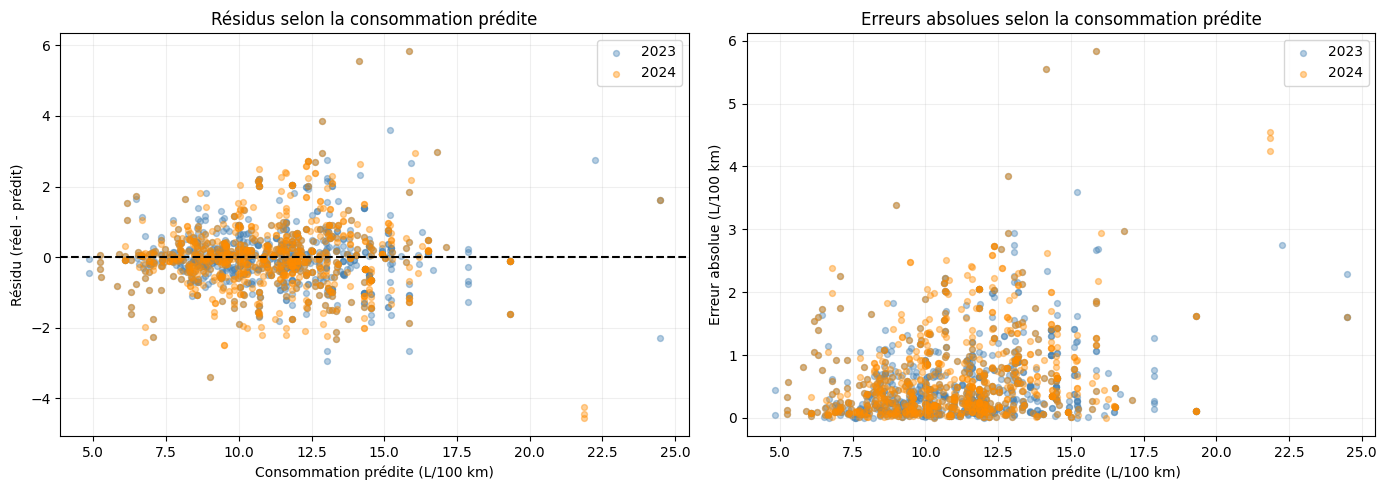

In [ ]:
# M027 - Étape 2
# Visualisation des résidus selon la consommation prédite

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

couleurs = {
    2023: "steelblue",
    2024: "darkorange"
}

# Graphique 1 : Résidus
for annee in [2023, 2024]:
    donnees = donnees_m027.loc[
        donnees_m027["Année modèle"] == annee
    ]

    axes[0].scatter(
        donnees["Prédiction (L/100 km)"],
        donnees["Résidu"],
        alpha=0.4,
        s=18,
        label=str(annee),
        color=couleurs[annee]
    )

axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Résidus selon la consommation prédite")
axes[0].set_xlabel("Consommation prédite (L/100 km)")
axes[0].set_ylabel("Résidu (réel - prédit)")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Graphique 2 : Erreurs absolues
for annee in [2023, 2024]:
    donnees = donnees_m027.loc[
        donnees_m027["Année modèle"] == annee
    ]

    axes[1].scatter(
        donnees["Prédiction (L/100 km)"],
        donnees["Erreur absolue"],
        alpha=0.4,
        s=18,
        label=str(annee),
        color=couleurs[annee]
    )

axes[1].set_title("Erreurs absolues selon la consommation prédite")
axes[1].set_xlabel("Consommation prédite (L/100 km)")
axes[1].set_ylabel("Erreur absolue (L/100 km)")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


**Interprétation des graphiques - M027**

Les graphiques des résidus et des erreurs absolues montrent que la dispersion des erreurs tend à augmenter avec la consommation prédite.

Pour les véhicules dont la consommation prédite est relativement faible, les résidus sont généralement concentrés autour de zéro et les erreurs absolues demeurent limitées.

Lorsque la consommation prédite augmente, les erreurs deviennent plus dispersées. Certaines observations présentent des écarts importants entre la consommation réelle et la consommation prédite, dans les deux directions.

Cette tendance est visible pour les années 2023 et 2024. Les résultats numériques montrent également que la MAE est plus élevée en 2024 dans chacune des cinq plages de consommation étudiées.

Ces observations suggèrent que la précision du modèle varie selon le niveau de consommation. Elles sont compatibles avec une dispersion non constante des erreurs, sans constituer à elles seules une démonstration statistique d'hétéroscédasticité.

In [ ]:
# M027 - Étape 3
# Corrélation entre consommation prédite et erreur absolue

from scipy.stats import pearsonr, spearmanr

resultats_correlation = []

for annee in [2023, 2024]:

    donnees = donnees_m027.loc[
        donnees_m027["Année modèle"] == annee
    ]

    x = donnees["Prédiction (L/100 km)"]
    y = donnees["Erreur absolue"]

    pearson, p_pearson = pearsonr(x, y)
    spearman, p_spearman = spearmanr(x, y)

    resultats_correlation.append({
        "Année": annee,
        "N": len(donnees),
        "Pearson": pearson,
        "p_Pearson": p_pearson,
        "Spearman": spearman,
        "p_Spearman": p_spearman
    })

tableau_correlation_m027 = pd.DataFrame(
    resultats_correlation
)

print("Corrélations entre consommation prédite et erreur absolue :")
print(
    tableau_correlation_m027
    .round(4)
    .to_string(index=False)
)


Corrélations entre consommation prédite et erreur absolue :
 Année   N  Pearson  p_Pearson  Spearman  p_Spearman
  2023 919   0.2486        0.0    0.2316         0.0
  2024 789   0.2689        0.0    0.2379         0.0


**Conclusion - M027**

L'analyse des résidus montre que les erreurs de prédiction du modèle forêt aléatoire ont tendance à augmenter avec la consommation prédite des véhicules.

Cette tendance apparaît dans les tableaux de statistiques descriptives, les graphiques et les coefficients de corrélation.

En 2024, la MAE passe de 0,411 L/100 km pour les prédictions inférieures à 8 L/100 km à 0,940 L/100 km pour les prédictions d'au moins 14 L/100 km. L'écart-type des résidus augmente également, passant de 0,667 à 1,452 L/100 km.

Les coefficients de corrélation de Pearson sont de 0,2486 en 2023 et de 0,2689 en 2024. Ceux de Spearman sont respectivement de 0,2316 et de 0,2379. Ces résultats indiquent une association positive, mais relativement faible, entre la consommation prédite et l'erreur absolue.

La MAE augmente également entre 2023 et 2024 dans chacune des cinq plages de consommation étudiées.

Ces observations suggèrent que la précision du modèle varie selon le niveau de consommation prédite et que la diminution de la performance en 2024 est relativement généralisée.

Toutefois, cette analyse demeure exploratoire. Elle ne permet pas de démontrer formellement une hétéroscédasticité ni d'identifier les causes des erreurs observées.

---

**M028 - Consolidation des résultats de modélisation**

Dans cette manipulation, je vais regrouper les principaux résultats obtenus lors de l'évaluation des modèles prédictifs.

Je commencerai par consolider les performances du modèle forêt aléatoire entraîné sur les données de 2015 à 2022 et évalué sur les années 2023 et 2024.

Je calculerai les indicateurs MAE, RMSE et R² pour l'ensemble du jeu de test ainsi que pour chaque année séparément.

Cette synthèse permettra de présenter les résultats de manière uniforme et facilitera leur utilisation dans le rapport final.

In [ ]:
# M028 - Étape 1
# Synthèse des performances du modèle forêt aléatoire (Random Forest)

resultats_synthese = []

# Évaluation globale et par année
periodes = [
    ("2023-2024", [2023, 2024]),
    ("2023", [2023]),
    ("2024", [2024])
]

for nom_periode, annees in periodes:

    donnees = resultats_m020.loc[
        resultats_m020["Année modèle"].isin(annees)
    ]

    valeurs_reelles = donnees["Combinée (L/100 km)"]
    predictions = donnees["Prédiction (L/100 km)"]

    resultats_synthese.append({
        "Modèle": "Forêt aléatoire",
        "Entraînement": "2015-2022",
        "Évaluation": nom_periode,
        "N": len(donnees),
        "MAE": mean_absolute_error(
            valeurs_reelles, predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            valeurs_reelles, predictions
        )),
        "R2": r2_score(
            valeurs_reelles, predictions
        )
    })

tableau_m028 = pd.DataFrame(resultats_synthese)

print("Synthèse des performances du modèle forêt aléatoire :")
print(
    tableau_m028
    .round(3)
    .to_string(index=False)
)

# Vérifications
assert tableau_m028.loc[0, "N"] == 1708
assert tableau_m028.loc[1, "N"] == 919
assert tableau_m028.loc[2, "N"] == 789

assert np.isclose(
    tableau_m028.loc[0, "MAE"],
    mae,
    atol=1e-10
)

print("\nVérification : OK")


Synthèse des performances du modèle forêt aléatoire :
         Modèle Entraînement Évaluation    N   MAE  RMSE    R2
Forêt aléatoire    2015-2022  2023-2024 1708 0.610 0.910 0.897
Forêt aléatoire    2015-2022       2023  919 0.553 0.834 0.914
Forêt aléatoire    2015-2022       2024  789 0.676 0.991 0.877

Vérification : OK


**M028 - Comparaison avec les modèles de référence**

Afin de vérifier l'intérêt du modèle forêt aléatoire, je vais comparer ses performances avec celles de deux modèles de référence : un modèle naïf (DummyRegressor) et une régression linéaire.

Les trois modèles seront entraînés sur les années 2015 à 2022 et évalués sur les années 2023 et 2024.

Cette comparaison permettra de déterminer si la complexité supplémentaire du modèle forêt aléatoire apporte une amélioration mesurable de la précision des prédictions.

In [ ]:
# M028 - Étape 2
# Comparaison des modèles sur le même jeu de test

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.base import clone

# Modèle naïf : prédit la moyenne de l'entraînement
modele_naif = DummyRegressor(strategy="mean")
modele_naif.fit(X_train, y_train)

# Régression linéaire avec la même préparation
modele_lineaire = Pipeline([
    ("preparation", clone(preparation)),
    ("modele", LinearRegression())
])

modele_lineaire.fit(X_train, y_train)

# Prédictions
pred_naif = modele_naif.predict(X_test)
pred_lineaire = modele_lineaire.predict(X_test)

# Tableau comparatif
comparaison_modeles = []

for nom, predictions in [
    ("Modèle naïf", pred_naif),
    ("Régression linéaire", pred_lineaire),
    ("Forêt aléatoire", y_pred_rf)
]:
    comparaison_modeles.append({
        "Modèle": nom,
        "Entraînement": "2015-2022",
        "Évaluation": "2023-2024",
        "N": len(y_test),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions)
    })

tableau_comparaison_m028 = pd.DataFrame(
    comparaison_modeles
)

print("Comparaison des trois modèles :")
print(
    tableau_comparaison_m028
    .round(3)
    .to_string(index=False)
)

# Amélioration de la MAE du modèle forêt aléatoire (Random Forest)
mae_naif = tableau_comparaison_m028.loc[
    tableau_comparaison_m028["Modèle"] == "Modèle naïf",
    "MAE"
].iloc[0]

mae_lineaire = tableau_comparaison_m028.loc[
    tableau_comparaison_m028["Modèle"] == "Régression linéaire",
    "MAE"
].iloc[0]

mae_rf = tableau_comparaison_m028.loc[
    tableau_comparaison_m028["Modèle"] == "Forêt aléatoire",
    "MAE"
].iloc[0]

print("\nRéduction de la MAE du modèle Forêt aléatoire :")
print(
    f"Par rapport au modèle naïf : "
    f"{(1 - mae_rf / mae_naif) * 100:.1f} %"
)
print(
    f"Par rapport à la régression linéaire : "
    f"{(1 - mae_rf / mae_lineaire) * 100:.1f} %"
)


Comparaison des trois modèles :
             Modèle Entraînement Évaluation    N   MAE  RMSE     R2
        Modèle naïf    2015-2022  2023-2024 1708 2.227 2.840 -0.005
Régression linéaire    2015-2022  2023-2024 1708 0.958 1.287  0.793
    Forêt aléatoire    2015-2022  2023-2024 1708 0.610 0.910  0.897

Réduction de la MAE du modèle Forêt aléatoire :
Par rapport au modèle naïf : 72.6 %
Par rapport à la régression linéaire : 36.4 %


**Interprétation - Comparaison des modèles**

La comparaison des trois modèles montre que le forêt aléatoire obtient les meilleures performances sur les données de 2023 et 2024.

Sa MAE est de 0,610 L/100 km, comparativement à 0,958 L/100 km pour la régression linéaire et à 2,227 L/100 km pour le modèle naïf.

Le modèle forêt aléatoire réduit ainsi la MAE de 72,6 % par rapport au modèle naïf et de 36,4 % par rapport à la régression linéaire.

Son coefficient R² atteint 0,897, contre 0,793 pour la régression linéaire et −0,005 pour le modèle naïf.

Ces résultats indiquent que le modèle forêt aléatoire représente le meilleur choix parmi les trois modèles évalués selon les indicateurs retenus. Toutefois, cette conclusion concerne le jeu de test et le protocole utilisés et ne garantit pas des performances identiques sur d'autres années.

**M028 - Validation chronologique progressive**

Je vais reproduire la validation chronologique progressive réalisée précédemment afin de consolider les résultats dans un même notebook.

Pour chaque période, le modèle forêt aléatoire sera entraîné sur les années antérieures et évalué sur l'année suivante.

Cette méthode permet d'examiner la stabilité des performances dans le temps tout en respectant l'ordre chronologique des données.

Les résultats de ces validations seront présentés séparément de ceux du jeu de test final de 2023–2024.

In [ ]:
# M028 - Étape 3
# Validation chronologique progressive du modèle forêt aléatoire (Random Forest)

from sklearn.base import clone

validations = [
    (2019, 2020),
    (2020, 2021),
    (2021, 2022)
]

resultats_validation = []

for fin_train, annee_validation in validations:

    masque_train = (
        df_analyse["Année modèle"] <= fin_train
    )

    masque_validation = (
        df_analyse["Année modèle"] == annee_validation
    )

    X_train_temp = df_analyse.loc[
        masque_train, variables
    ]
    y_train_temp = df_analyse.loc[
        masque_train, cible
    ]

    X_validation = df_analyse.loc[
        masque_validation, variables
    ]
    y_validation = df_analyse.loc[
        masque_validation, cible
    ]

    # Nouveau modèle indépendant pour chaque période
    modele_temp = clone(modele_rf)

    modele_temp.fit(X_train_temp, y_train_temp)

    predictions = modele_temp.predict(X_validation)

    resultats_validation.append({
        "Entraînement": f"2015-{fin_train}",
        "Validation": annee_validation,
        "N_train": len(X_train_temp),
        "N_validation": len(X_validation),
        "MAE": mean_absolute_error(
            y_validation, predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_validation, predictions
        )),
        "R2": r2_score(
            y_validation, predictions
        )
    })

tableau_validation_m028 = pd.DataFrame(
    resultats_validation
)

print("Validation chronologique progressive :")
print(
    tableau_validation_m028
    .round(3)
    .to_string(index=False)
)


Validation chronologique progressive :
Entraînement  Validation  N_train  N_validation   MAE  RMSE    R2
   2015-2019        2020     5431           975 0.552 0.799 0.919
   2015-2020        2021     6406           970 0.585 0.848 0.914
   2015-2021        2022     7376           976 0.543 0.827 0.918


In [ ]:
# M028 - Étape 4
# Tableau chronologique consolidé

# Résultats des validations progressives
historique = tableau_validation_m028.rename(
    columns={"Validation": "Année évaluée"}
)[[
    "Année évaluée",
    "Entraînement",
    "N_validation",
    "MAE",
    "RMSE",
    "R2"
]].rename(
    columns={"N_validation": "N"}
).copy()

historique["Protocole"] = "Validation progressive"

# Résultats annuels du test final
test_final = tableau_m028.loc[
    tableau_m028["Évaluation"].isin(["2023", "2024"])
].copy()

test_final["Année évaluée"] = (
    test_final["Évaluation"].astype(int)
)

test_final = test_final[[
    "Année évaluée",
    "Entraînement",
    "N",
    "MAE",
    "RMSE",
    "R2"
]]

test_final["Protocole"] = "Test final"

# Consolidation
tableau_chronologique_m028 = pd.concat(
    [historique, test_final],
    ignore_index=True
).sort_values("Année évaluée")

tableau_chronologique_m028 = (
    tableau_chronologique_m028[[
        "Année évaluée",
        "Entraînement",
        "Protocole",
        "N",
        "MAE",
        "RMSE",
        "R2"
    ]]
)

print("Tableau chronologique consolidé :")
print(
    tableau_chronologique_m028
    .round(3)
    .to_string(index=False)
)

# Vérifications
assert len(tableau_chronologique_m028) == 5
assert tableau_chronologique_m028["N"].sum() == 4629

print("\nVérification : OK")


Tableau chronologique consolidé :
 Année évaluée Entraînement              Protocole   N   MAE  RMSE    R2
          2020    2015-2019 Validation progressive 975 0.552 0.799 0.919
          2021    2015-2020 Validation progressive 970 0.585 0.848 0.914
          2022    2015-2021 Validation progressive 976 0.543 0.827 0.918
          2023    2015-2022             Test final 919 0.553 0.834 0.914
          2024    2015-2022             Test final 789 0.676 0.991 0.877

Vérification : OK


**Interprétation - Validation chronologique**

La validation chronologique progressive du modèle forêt aléatoire donne des résultats relativement stables pour les années 2020, 2021 et 2022.

La MAE varie entre 0,543 et 0,585 L/100 km et le coefficient R² demeure supérieur à 0,91 pour chacune de ces trois années.

L'évaluation du modèle final, entraîné sur les années 2015 à 2022, donne une MAE de 0,553 L/100 km en 2023 et de 0,676 L/100 km en 2024.

Ces résultats montrent que le modèle conserve une bonne capacité prédictive sur plusieurs années, mais que sa précision diminue en 2024.

Les résultats doivent toutefois être interprétés en tenant compte des différences de protocole. Les validations de 2020 à 2022 utilisent des modèles réentraînés progressivement, tandis que les années 2023 et 2024 sont évaluées avec un même modèle entraîné jusqu'en 2022.

Cette analyse permet d'évaluer la stabilité temporelle des performances, sans garantir que le modèle conservera le même niveau de précision sur des données futures.

---

**M029 - Production des figures et tableaux définitifs**

Cette manipulation vise à produire les principales figures et les tableaux de synthèse destinés à la présentation des résultats du projet.

Je commencerai par représenter graphiquement l'évolution de l'erreur absolue moyenne (MAE) entre 2020 et 2024.

Les résultats des validations chronologiques progressives seront distingués de ceux du jeu de test final afin de tenir compte des différences de protocole d'évaluation.

Les figures seront enregistrées au format PNG avec une résolution de 300 DPI, afin de faciliter leur intégration dans les rapports.

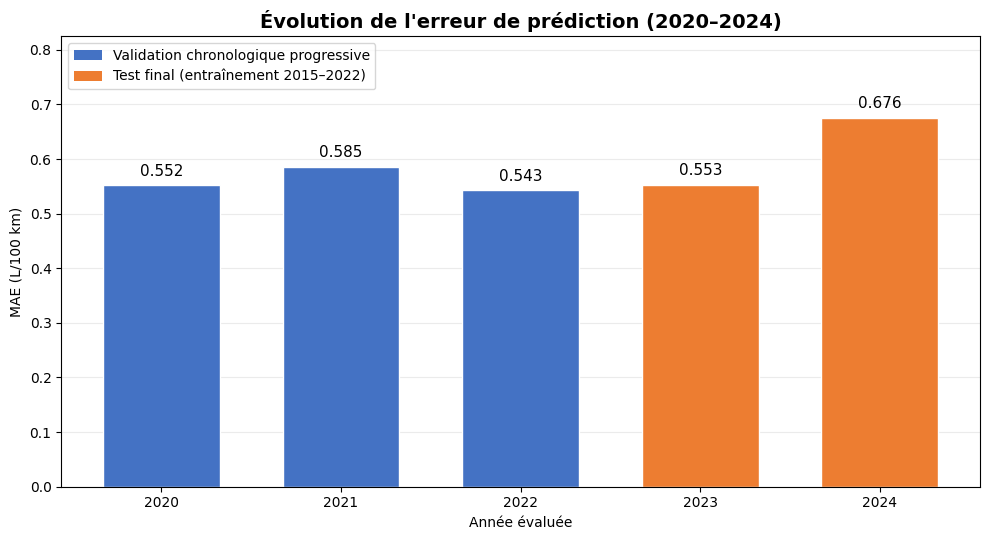

Figure enregistrée : figures_finales/M029_evolution_MAE_2020_2024.png


In [ ]:
# M029 - Étape 1
# Figure définitive : évolution chronologique de la MAE

import matplotlib.pyplot as plt
import os

# Dossier de sortie
dossier_figures = "figures_finales"
os.makedirs(dossier_figures, exist_ok=True)

donnees = tableau_chronologique_m028.sort_values(
    "Année évaluée"
)

annees = donnees["Année évaluée"].to_numpy()
mae = donnees["MAE"].to_numpy()

couleurs = [
    "#4472C4" if p == "Validation progressive"
    else "#ED7D31"
    for p in donnees["Protocole"]
]

fig, ax = plt.subplots(figsize=(10, 5.5))

barres = ax.bar(
    annees.astype(str),
    mae,
    color=couleurs,
    edgecolor="white",
    width=0.65
)

# Valeurs sur les barres
for barre, valeur in zip(barres, mae):
    ax.text(
        barre.get_x() + barre.get_width() / 2,
        barre.get_height() + 0.012,
        f"{valeur:.3f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title(
    "Évolution de l'erreur de prédiction (2020–2024)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Année évaluée")
ax.set_ylabel("MAE (L/100 km)")
ax.set_ylim(0, max(mae) * 1.22)

# Légende
from matplotlib.patches import Patch

legende = [
    Patch(
        facecolor="#4472C4",
        label="Validation chronologique progressive"
    ),
    Patch(
        facecolor="#ED7D31",
        label="Test final (entraînement 2015–2022)"
    )
]

ax.legend(handles=legende, loc="upper left")

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

chemin_figure = os.path.join(
    dossier_figures,
    "M029_evolution_MAE_2020_2024.png"
)

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure enregistrée :", chemin_figure)


**Interprétation - Figure M029-1**

La figure présente l'évolution de l'erreur absolue moyenne (MAE) du modèle forêt aléatoire pour les années 2020 à 2024.

Les performances demeurent relativement stables de 2020 à 2023, avec des valeurs de MAE comprises entre 0,543 et 0,585 L/100 km.

En 2024, la MAE augmente à 0,676 L/100 km, comparativement à 0,553 L/100 km en 2023, ce qui représente une hausse d'environ 22,3 %.

Cette augmentation indique une diminution de la précision des prédictions en 2024.

Les évaluations de 2020 à 2022 reposent sur une validation chronologique progressive, tandis que celles de 2023 et 2024 utilisent le modèle final entraîné sur les données de 2015 à 2022. Les résultats sont donc présentés avec une distinction explicite entre les protocoles.

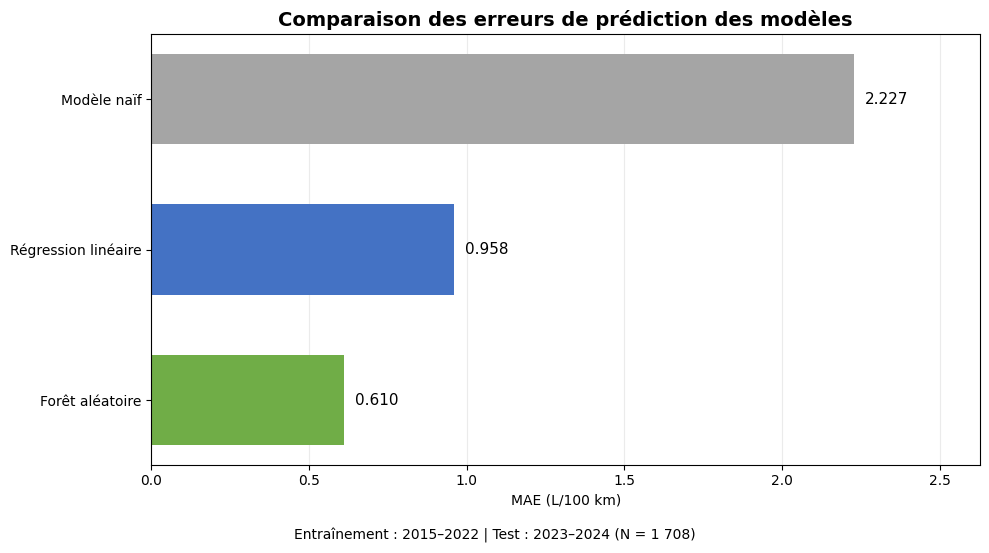

Figure enregistrée : figures_finales/M029_comparaison_modeles_MAE.png


In [ ]:
# M029 - Étape 2
# Figure définitive : Comparaison des trois modèles

import matplotlib.pyplot as plt
import os

donnees = tableau_comparaison_m028.sort_values(
    "MAE", ascending=False
)

modeles = donnees["Modèle"]
valeurs_mae = donnees["MAE"]

couleurs = [
    "#A5A5A5" if modele == "Modèle naïf"
    else "#4472C4" if modele == "Régression linéaire"
    else "#70AD47"
    for modele in modeles
]

fig, ax = plt.subplots(figsize=(10, 5.5))

barres = ax.barh(
    modeles,
    valeurs_mae,
    color=couleurs,
    height=0.6
)

# Le modèle naïf apparaît en haut
ax.invert_yaxis()

# Affichage des valeurs
for barre, valeur in zip(barres, valeurs_mae):
    ax.text(
        valeur + 0.035,
        barre.get_y() + barre.get_height() / 2,
        f"{valeur:.3f}",
        va="center",
        fontsize=11
    )

ax.set_title(
    "Comparaison des erreurs de prédiction des modèles",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("MAE (L/100 km)")
ax.set_xlim(0, max(valeurs_mae) * 1.18)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

# Précision sur le protocole
fig.text(
    0.5, 0.01,
    "Entraînement : 2015–2022 | Test : 2023–2024 (N = 1 708)",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

chemin_figure = os.path.join(
    dossier_figures,
    "M029_comparaison_modeles_MAE.png"
)

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure enregistrée :", chemin_figure)


**Interprétation - Figure M029-2**

La figure compare les erreurs absolues moyennes (MAE) des trois modèles prédictifs évalués sur les données de 2023 et 2024.

Le modèle forêt aléatoire obtient la plus faible MAE, soit 0,610 L/100 km, suivi de la régression linéaire avec 0,958 L/100 km et du modèle naïf avec 2,227 L/100 km.

La réduction de la MAE atteint 36,4 % par rapport à la régression linéaire et 72,6 % par rapport au modèle naïf.

Ces résultats confirment que le forêt aléatoire est le modèle le plus précis parmi les trois approches étudiées, selon la MAE et sur le jeu de test retenu.

**M029 - Comparaison des consommations réelles et prédites**

Cette figure présente la relation entre les consommations réelles et les consommations prédites par le modèle forêt aléatoire pour les années 2023 et 2024.

Chaque point correspond à une observation du jeu de test. La diagonale représente une prédiction parfaite, où la consommation prédite est égale à la consommation réelle.

La dispersion des points autour de cette diagonale permettra d'évaluer visuellement la précision des prédictions et d'identifier les observations présentant des erreurs importantes.

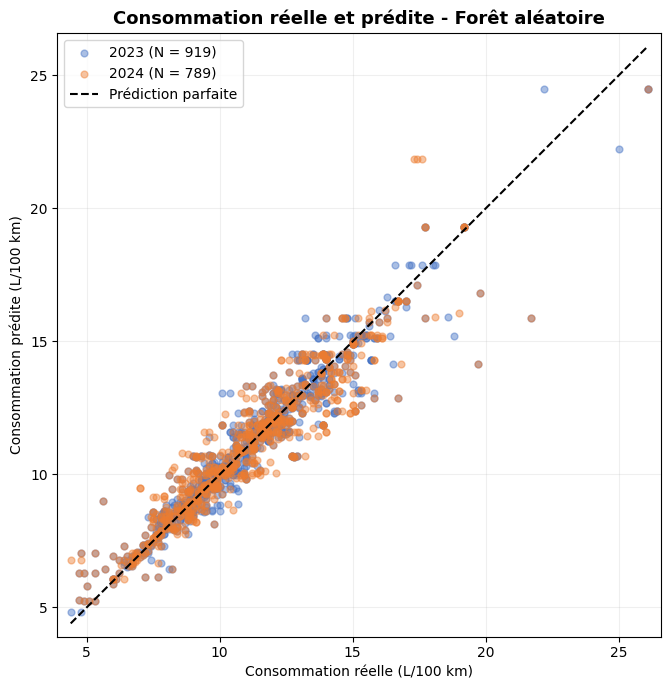

Figure enregistrée : figures_finales/M029_reel_vs_predit_2023_2024.png


In [ ]:
# M029 - Étape 3
# Figure définitive : consommation réelle vs prédite

import matplotlib.pyplot as plt
import os
import numpy as np

fig, ax = plt.subplots(figsize=(8, 7))

couleurs = {
    2023: "#4472C4",
    2024: "#ED7D31"
}

for annee in [2023, 2024]:

    donnees = resultats_m020.loc[
        resultats_m020["Année modèle"] == annee
    ]

    ax.scatter(
        donnees["Combinée (L/100 km)"],
        donnees["Prédiction (L/100 km)"],
        alpha=0.45,
        s=24,
        color=couleurs[annee],
        label=f"{annee} (N = {len(donnees)})"
    )

# Diagonale : prédiction parfaite
minimum = min(
    resultats_m020["Combinée (L/100 km)"].min(),
    resultats_m020["Prédiction (L/100 km)"].min()
)

maximum = max(
    resultats_m020["Combinée (L/100 km)"].max(),
    resultats_m020["Prédiction (L/100 km)"].max()
)

ax.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Prédiction parfaite"
)

ax.set_xlim(minimum - 0.5, maximum + 0.5)
ax.set_ylim(minimum - 0.5, maximum + 0.5)
ax.set_aspect("equal", adjustable="box")

ax.set_title(
    "Consommation réelle et prédite - Forêt aléatoire",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Consommation réelle (L/100 km)")
ax.set_ylabel("Consommation prédite (L/100 km)")

ax.legend()
ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

chemin_figure = os.path.join(
    dossier_figures,
    "M029_reel_vs_predit_2023_2024.png"
)

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure enregistrée :", chemin_figure)


**Interprétation - Figure M029-3**

La figure présente les consommations réelles et les consommations prédites par le modèle forêt aléatoire pour les 1 708 observations du jeu de test 2023–2024.

La majorité des points se trouvent près de la diagonale représentant une prédiction parfaite, ce qui indique une bonne correspondance générale entre les valeurs réelles et prédites.

Toutefois, la dispersion des points semble augmenter pour les véhicules présentant des consommations élevées. Certaines configurations affichent également des erreurs de prédiction importantes, notamment des sous-estimations de consommation.

Ces observations sont cohérentes avec l'analyse des résidus réalisée précédemment, qui a mis en évidence une association positive entre le niveau de consommation prédite et l'erreur absolue.

Le graphique illustre ainsi les bonnes performances générales du modèle, tout en mettant en évidence certaines limites pour les configurations présentant des consommations élevées.

**M029 - Distribution des erreurs absolues**

Cette figure présente la distribution des erreurs absolues du modèle forêt aléatoire pour les années 2023 et 2024.

L'objectif est d'examiner la concentration des erreurs près de zéro, la fréquence des erreurs importantes et les différences entre les deux années.

Les distributions seront normalisées afin de tenir compte du nombre différent d'observations en 2023 et en 2024.

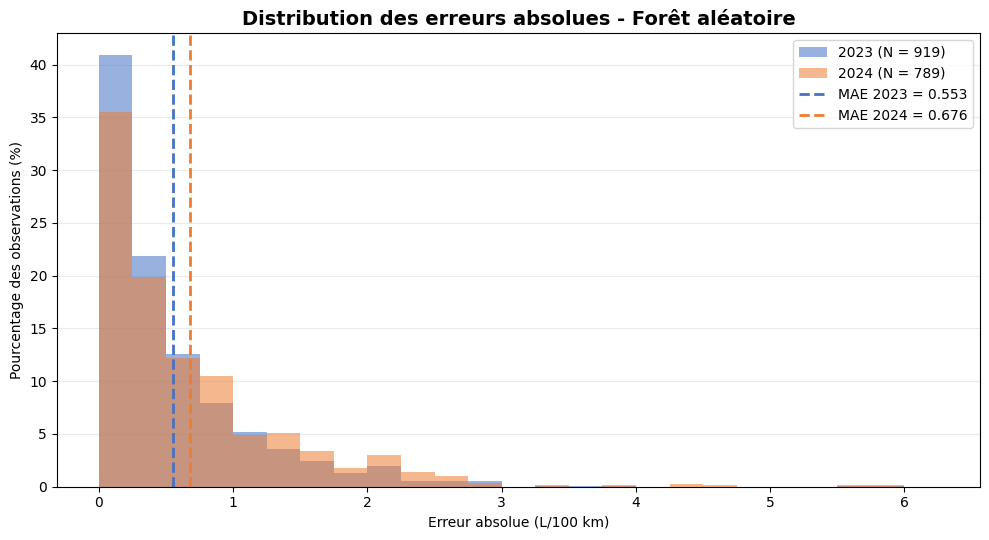

Figure enregistrée : figures_finales/M029_distribution_erreurs_absolues.png

Année 2023
MAE : 0.553
Médiane : 0.331
Erreurs < 1 L/100 km : 83.4 %
Erreurs >= 2 L/100 km : 4.1 %

Année 2024
MAE : 0.676
Médiane : 0.439
Erreurs < 1 L/100 km : 78.1 %
Erreurs >= 2 L/100 km : 6.7 %


In [ ]:
# M029 - Étape 4
# Figure définitive : distribution des erreurs absolues

import matplotlib.pyplot as plt
import numpy as np
import os

fig, ax = plt.subplots(figsize=(10, 5.5))

erreurs_2023 = resultats_m020.loc[
    resultats_m020["Année modèle"] == 2023,
    "Erreur absolue"
]

erreurs_2024 = resultats_m020.loc[
    resultats_m020["Année modèle"] == 2024,
    "Erreur absolue"
]

# Classes identiques pour les deux années
limite = np.ceil(
    resultats_m020["Erreur absolue"].max() * 2
) / 2

classes = np.arange(0, limite + 0.26, 0.25)

ax.hist(
    erreurs_2023,
    bins=classes,
    weights=np.ones(len(erreurs_2023)) / len(erreurs_2023) * 100,
    alpha=0.55,
    color="#4472C4",
    label="2023 (N = 919)"
)

ax.hist(
    erreurs_2024,
    bins=classes,
    weights=np.ones(len(erreurs_2024)) / len(erreurs_2024) * 100,
    alpha=0.55,
    color="#ED7D31",
    label="2024 (N = 789)"
)

# MAE de chaque année
ax.axvline(
    erreurs_2023.mean(),
    color="#4472C4",
    linestyle="--",
    linewidth=2,
    label=f"MAE 2023 = {erreurs_2023.mean():.3f}"
)

ax.axvline(
    erreurs_2024.mean(),
    color="#ED7D31",
    linestyle="--",
    linewidth=2,
    label=f"MAE 2024 = {erreurs_2024.mean():.3f}"
)

ax.set_title(
    "Distribution des erreurs absolues - Forêt aléatoire",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Erreur absolue (L/100 km)")
ax.set_ylabel("Pourcentage des observations (%)")

ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

chemin_figure = os.path.join(
    dossier_figures,
    "M029_distribution_erreurs_absolues.png"
)

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure enregistrée :", chemin_figure)

# Statistiques complémentaires
for annee, erreurs in [
    (2023, erreurs_2023),
    (2024, erreurs_2024)
]:
    print(f"\nAnnée {annee}")
    print(f"MAE : {erreurs.mean():.3f}")
    print(f"Médiane : {erreurs.median():.3f}")
    print(
        f"Erreurs < 1 L/100 km : "
        f"{(erreurs < 1).mean() * 100:.1f} %"
    )
    print(
        f"Erreurs >= 2 L/100 km : "
        f"{(erreurs >= 2).mean() * 100:.1f} %"
    )


**Interprétation - Figure M029-4**

La distribution des erreurs absolues du modèle forêt aléatoire montre une concentration importante des observations près de zéro.

La fréquence des erreurs diminue progressivement lorsque leur amplitude augmente, ce qui indique que les erreurs importantes sont relativement peu fréquentes.

La distribution de 2024 présente une proportion visuellement moins élevée de très petites erreurs et une présence légèrement plus importante d'erreurs de plus grande amplitude.

Cette observation est cohérente avec l'augmentation de la MAE, qui passe de 0,553 L/100 km en 2023 à 0,676 L/100 km en 2024.

Certaines configurations présentent néanmoins des erreurs extrêmes de plusieurs L/100 km, ce qui constitue une limite importante pour les prédictions individuelles.

Cette figure complète les indicateurs de performance globaux en montrant la répartition des erreurs entre les observations.

In [ ]:
# M029 - Étape 5
# Synthèse des erreurs absolues par année

resultats_distribution = []

for annee in [2023, 2024]:

    erreurs = resultats_m020.loc[
        resultats_m020["Année modèle"] == annee,
        "Erreur absolue"
    ]

    resultats_distribution.append({
        "Année": annee,
        "N": len(erreurs),
        "MAE": erreurs.mean(),
        "Médiane": erreurs.median(),
        "Erreur < 0.5 (%)": (erreurs < 0.5).mean() * 100,
        "Erreur < 1 (%)": (erreurs < 1).mean() * 100,
        "Erreur >= 2 (%)": (erreurs >= 2).mean() * 100,
        "Erreur maximale": erreurs.max()
    })

tableau_distribution_m029 = pd.DataFrame(
    resultats_distribution
)

print("Distribution des erreurs absolues :")
print(
    tableau_distribution_m029
    .round(2)
    .to_string(index=False)
)

# Vérification des effectifs
assert tableau_distribution_m029["N"].sum() == 1708

print("\nVérification : OK")


Distribution des erreurs absolues :
 Année   N  MAE  Médiane  Erreur < 0.5 (%)  Erreur < 1 (%)  Erreur >= 2 (%)  Erreur maximale
  2023 919 0.55     0.33             62.79           83.35             4.13             5.83
  2024 789 0.68     0.44             55.39           78.07             6.72             5.83

Vérification : OK


**Interprétation - Distribution des erreurs absolues**

L'analyse quantitative de la distribution des erreurs confirme une diminution de la précision du modèle forêt aléatoire entre 2023 et 2024.

La proportion des prédictions présentant une erreur inférieure à 1 L/100 km passe de 83,35 % en 2023 à 78,07 % en 2024.

Parallèlement, la proportion des observations dont l'erreur atteint au moins 2 L/100 km augmente de 4,13 % à 6,72 %.

L'erreur absolue médiane augmente également, passant de 0,33 à 0,44 L/100 km.

Ces résultats montrent que la hausse de la MAE en 2024 ne s'explique pas uniquement par quelques erreurs extrêmes. Elle s'accompagne également d'une diminution de la proportion des prédictions très précises.

Le modèle conserve néanmoins une erreur inférieure à 1 L/100 km pour 78,07 % des observations de 2024.

**M029 - Importance des variables explicatives**

Cette analyse vise à déterminer quelles variables contribuent le plus à la précision prédictive du modèle forêt aléatoire.

L'importance des variables sera évaluée par permutation sur le jeu de test 2023–2024.

Pour chaque variable explicative, les valeurs seront mélangées aléatoirement afin de mesurer l'augmentation de l'erreur absolue moyenne (MAE).

Une augmentation importante de la MAE indique que le modèle dépend fortement de cette variable pour produire des prédictions précises.

Cette méthode mesure l'importance prédictive des variables et ne permet pas d'établir une relation causale.

Importance des variables par permutation :
             Variable  Importance_MAE  Ecart_type
        Cylindrée (L)          1.8118      0.0437
Catégorie de véhicule          0.3902      0.0103
         Transmission          0.3886      0.0215
    Type de carburant          0.2565      0.0078
            Cylindres          0.0934      0.0057
         Année modèle          0.0000      0.0000


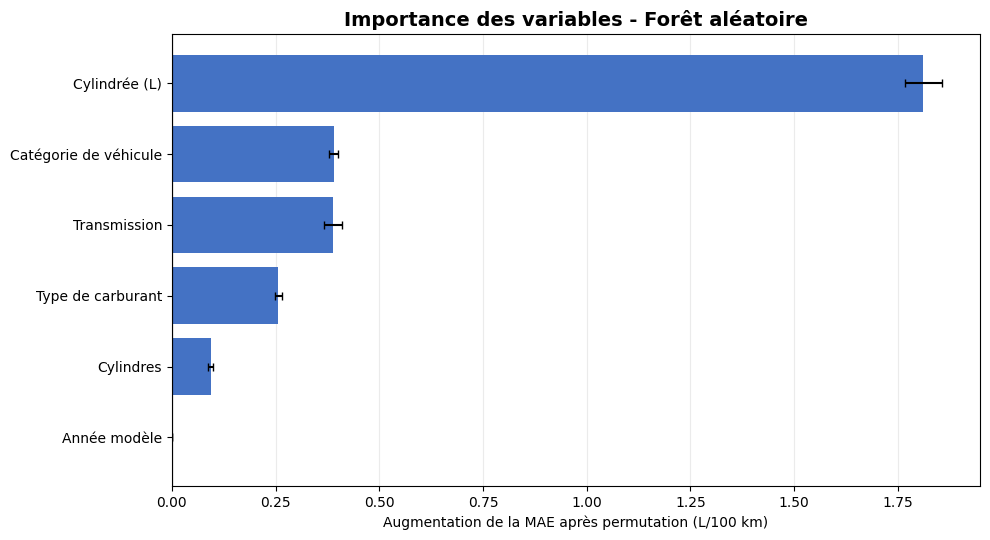


Figure enregistrée : figures_finales/M029_importance_variables_permutation.png


In [ ]:
# M029 - Étape 6
# Importance des variables par permutation

from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import pandas as pd
import os

importance_m029 = permutation_importance(
    modele_rf,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

tableau_importance_m029 = pd.DataFrame({
    "Variable": X_test.columns,
    "Importance_MAE": importance_m029.importances_mean,
    "Ecart_type": importance_m029.importances_std
}).sort_values(
    "Importance_MAE",
    ascending=True
)

print("Importance des variables par permutation :")
print(
    tableau_importance_m029
    .sort_values("Importance_MAE", ascending=False)
    .round(4)
    .to_string(index=False)
)

# Figure
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.barh(
    tableau_importance_m029["Variable"],
    tableau_importance_m029["Importance_MAE"],
    xerr=tableau_importance_m029["Ecart_type"],
    color="#4472C4",
    capsize=3
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_title(
    "Importance des variables - Forêt aléatoire",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Augmentation de la MAE après permutation (L/100 km)"
)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

chemin_figure = os.path.join(
    dossier_figures,
    "M029_importance_variables_permutation.png"
)

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure enregistrée :", chemin_figure)


**Interprétation - Figure M029-5**

L'analyse de l'importance des variables par permutation montre que la cylindrée constitue la variable explicative la plus importante pour les prédictions du modèle forêt aléatoire.

La permutation de cette variable entraîne une augmentation moyenne de la MAE de 1,8118 L/100 km, soit une dégradation nettement supérieure à celle observée pour les autres variables.

La catégorie de véhicule et la transmission occupent les deuxième et troisième positions, avec des augmentations respectives de 0,3902 et 0,3886 L/100 km.

Le type de carburant présente également une contribution notable, tandis que le nombre de cylindres apporte une contribution additionnelle plus limitée.

L'année modèle présente une importance nulle selon cette méthode et sur le jeu de test étudié.

Ces résultats permettent d'identifier les variables dont dépend le plus la précision du modèle. Toutefois, ils ne doivent pas être interprétés comme des mesures d'effets causaux. Les corrélations entre les variables explicatives peuvent également influencer les importances estimées.

---

**M030 - Exportation et vérification des résultats**

Cette dernière manipulation vise à préparer les résultats définitifs du projet en vue de leur intégration dans les rapports.

Les tableaux de synthèse seront exportés au format CSV et les figures déjà produites seront regroupées dans une archive ZIP.

Une vérification permettra de confirmer la présence des fichiers attendus et la cohérence des principaux résultats numériques.

Cette étape facilitera la conservation des résultats et leur réutilisation sans devoir exécuter à nouveau l'ensemble des analyses.

In [ ]:
# M030 - Étape 1
# Exportation des tableaux et figures définitifs

import os
import shutil
import numpy as np

dossier_export = "resultats_finaux"
dossier_tableaux = os.path.join(
    dossier_export, "tableaux"
)
dossier_images = os.path.join(
    dossier_export, "figures"
)

os.makedirs(dossier_tableaux, exist_ok=True)
os.makedirs(dossier_images, exist_ok=True)

# Tableaux définitifs
tableaux = {
    "comparaison_modeles.csv":
        tableau_comparaison_m028,
    "performances_chronologiques.csv":
        tableau_chronologique_m028,
    "distribution_erreurs.csv":
        tableau_distribution_m029,
    "importance_variables.csv":
        tableau_importance_m029
}

for nom_fichier, tableau in tableaux.items():
    chemin = os.path.join(
        dossier_tableaux, nom_fichier
    )

    tableau.to_csv(
        chemin,
        index=False,
        encoding="utf-8-sig"
    )

# Copie des figures déjà créées
figures_attendues = [
    "M029_evolution_MAE_2020_2024.png",
    "M029_comparaison_modeles_MAE.png",
    "M029_reel_vs_predit_2023_2024.png",
    "M029_distribution_erreurs_absolues.png",
    "M029_importance_variables_permutation.png"
]

for nom_fichier in figures_attendues:
    source = os.path.join(
        dossier_figures, nom_fichier
    )

    assert os.path.isfile(source), (
        f"Figure introuvable : {source}"
    )

    shutil.copy2(
        source,
        os.path.join(dossier_images, nom_fichier)
    )

# Vérifications numériques
assert len(tableau_comparaison_m028) == 3
assert len(tableau_chronologique_m028) == 5
assert len(tableau_distribution_m029) == 2
assert len(tableau_importance_m029) == 6

assert np.isclose(
    tableau_comparaison_m028.loc[
        tableau_comparaison_m028["Modèle"] ==
        "Forêt aléatoire", "MAE"
    ].iloc[0],
    0.610,
    atol=0.001
)

# Création de l'archive ZIP
chemin_zip = shutil.make_archive(
    dossier_export,
    "zip",
    dossier_export
)

print("Exportation terminée.")
print(f"Tableaux CSV : {len(tableaux)}")
print(f"Figures PNG : {len(figures_attendues)}")
print(f"Archive créée : {chemin_zip}")
print("Vérifications : OK")


Exportation terminée.
Tableaux CSV : 4
Figures PNG : 5
Archive créée : /content/resultats_finaux.zip
Vérifications : OK


In [ ]:
from google.colab import files

files.download("/content/resultats_finaux.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>